# Fase 1 · Etapa 1.3b — Qualidade dos canais de aceleração

> **Bases de dados usadas:** **dados do pesquisador** — 144 registros da 2ª campanha
> (`Acelerômetro 1`, `Acelerômetro 2` [g]); a 1ª campanha só na tabela de recorte.
> Referência externa: fundo de escala ±5 V / 100 mV/g = ±50 g (NI 9234 + PCB 352C33;
> a faixa de medição do 352C33 também é ±50 g pk).

Perguntas: (1) houve **saturação**? (2) qual o **piso de ruído** e a **relação sinal/ruído**?
(3) a resposta **decai até o ruído** antes do fim da janela de 5 s (senão há vazamento
espectral com janela retangular)? (4) a estrutura **já vibrava** antes do golpe?
(5) há **offset DC**? (a uniformidade da amostragem já foi conferida na Etapa 1.1.)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dampid.eda import quality as q
from dampid.io.catalog import load_catalog
from dampid.io.ni_csv import read_ni_csv

cat = load_catalog("data/catalog.yaml")
sv = pd.read_csv("data/processed/fase1_survey.csv")
c2 = sv[sv.campaign == 2].copy()

## 1. Saturação (|a| ≥ 98 % de 50 g = 49 g)
Um acelerômetro saturado corta os picos: a resposta registrada deixa de ser linear na
força e a FRF de todo o registro fica distorcida (a energia cortada some, e harmônicos
aparecem). Não há como corrigir depois. O trecho **depois** do último recorte continua
válido para métodos no tempo (decaimento livre), se for longo.

In [2]:
clip = c2.groupby("config").agg(
    n=("id", "size"),
    acel1_saturado=("a0_n_clipped", lambda s: int((s > 0).sum())),
    acel2_saturado=("a1_n_clipped", lambda s: int((s > 0).sum())),
    ambos=("id", lambda s: int(((c2.loc[s.index, "a0_n_clipped"] > 0)
                                & (c2.loc[s.index, "a1_n_clipped"] > 0)).sum())),
    fim_do_recorte_ms_max=("a0_clip_end_after_impact_ms", "max"),
)
print(clip.to_string())
lst = c2[(c2.a0_n_clipped > 0) | (c2.a1_n_clipped > 0)]
print("\nRegistros com saturação:")
print(lst[["id", "a0_n_clipped", "a0_clip_end_after_impact_ms", "a1_n_clipped",
           "a1_clip_end_after_impact_ms", "F_peak_N"]].round(1).to_string(index=False))
c1 = sv[sv.campaign == 1]
print("\n1ª campanha — Input 0 saturado em:", list(c1.loc[c1.a0_n_clipped > 0, "id"]))

                      n  acel1_saturado  acel2_saturado  ambos  fim_do_recorte_ms_max
config                                                                               
LL_ACO               16               1               1      1              80.781250
LL_ACRILICO          16               5               5      5               6.210938
LL_AL                16               1               1      1               6.992188
LL_FIB_CARBONO       16              16              16     16              25.546875
LL_FIB_VIDRO_0       16               0               0      0                    NaN
LL_FIB_VIDRO_90      16               0               1      0                    NaN
LL_PLA_CAVERNA       16               0               0      0                    NaN
LL_PLA_LONGARINA_0   16               1               0      0               0.859375
LL_PLA_LONGARINA_90  16               1               0      0               0.742188

Registros com saturação:
                    id  a0_n

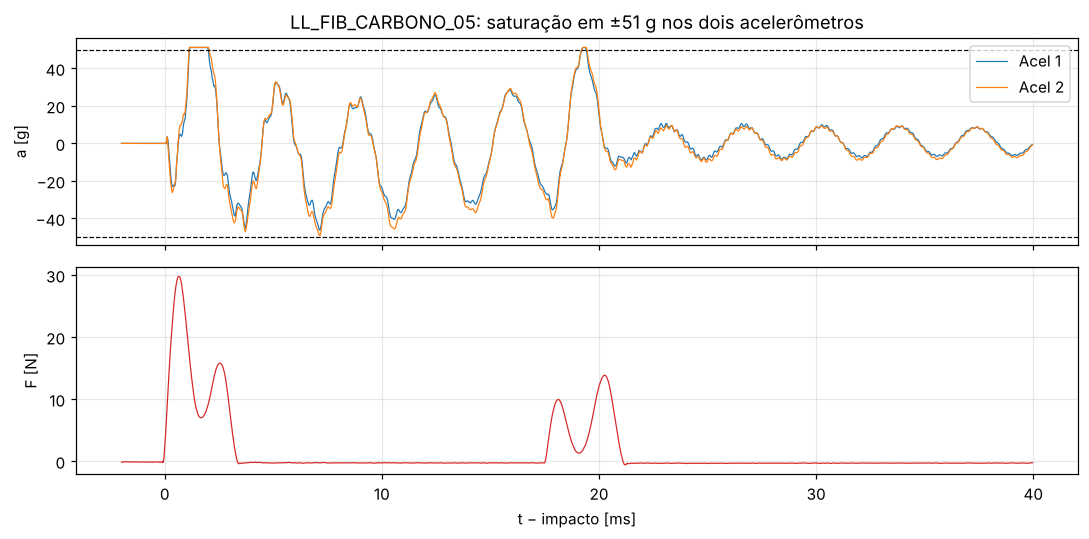

In [3]:
e = next(x for x in cat.entries if x.id == "LL_FIB_CARBONO_05")
r = read_ni_csv("data/raw/" + e.path)
fs = r.fs_hz
P = q.find_pulses(r.data[2], fs)
p = P[q.main_pulse(P)]
sl = slice(p.i_start - int(2e-3 * fs), p.i_start + int(40e-3 * fs))
t = (np.arange(sl.stop - sl.start) - int(2e-3 * fs)) / fs * 1e3
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(t, r.data[0][sl], lw=0.8, label="Acel 1")
ax[0].plot(t, r.data[1][sl], lw=0.8, label="Acel 2")
ax[0].axhline(50, color="k", ls="--", lw=0.8)
ax[0].axhline(-50, color="k", ls="--", lw=0.8)
ax[0].set_ylabel("a [g]")
ax[0].legend()
ax[0].set_title("LL_FIB_CARBONO_05: saturação em ±51 g nos dois acelerômetros")
ax[1].plot(t, r.data[2][sl], color="C3", lw=0.8)
ax[1].set_ylabel("F [N]")
ax[1].set_xlabel("t − impacto [ms]")
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()

## 2. Piso de ruído, relação sinal/ruído e decaimento
* **piso de ruído** de referência por canal: mediana, nas configurações que ficam quietas,
  do menor RMS em janelas de 10 ms (≈ 0,5 mg rms; Etapa 1.2);
* **SNR** = RMS dos primeiros 50 ms após o golpe ÷ piso;
* **decaimento** = RMS dos últimos 0,1 s ÷ RMS dos primeiros 50 ms (dB);
* **fim acima do ruído** = RMS dos últimos 0,1 s ÷ piso (dB). Se for grande, o registro
  foi truncado com a estrutura ainda vibrando → vazamento na FFT retangular (D2.2 decide
  janela exponencial ou métodos no tempo);
* **pré-impacto** = RMS antes do golpe ÷ piso (dB): estrutura ainda vibrando de um golpe
  anterior → condição inicial não nula.

In [4]:
quiet = c2[c2.config != "LL_ACO"]
floor = {k: float(quiet[f"{k}_min_strms"].median()) for k in ("a0", "a1")}
print({k: f"{v * 1e3:.3f} mg rms" for k, v in floor.items()})
for k in ("a0", "a1"):
    c2[f"{k}_snr_db"] = 20 * np.log10(c2[f"{k}_post_rms"] / floor[k])
    c2[f"{k}_end_over_floor_db"] = 20 * np.log10(c2[f"{k}_end_rms"] / floor[k])
    c2[f"{k}_pre_over_floor_db"] = 20 * np.log10(c2[f"{k}_pre_rms"] / floor[k])
resp = c2.groupby("config")[[
    "a0_snr_db", "a1_snr_db", "a0_decay_db", "a1_decay_db", "a0_end_over_floor_db",
    "a1_end_over_floor_db", "a0_pre_over_floor_db", "a1_pre_over_floor_db", "a0_remaining_s",
]].median()
resp.columns = ["SNR1", "SNR2", "decai1", "decai2", "fim/ruído1", "fim/ruído2",
                "pré/ruído1", "pré/ruído2", "registro após golpe [s]"]
print(resp.round(1).to_string())
resp.round(2).to_csv("docs/reports/fase1/04_resposta_por_config.csv")

{'a0': '0.505 mg rms', 'a1': '0.485 mg rms'}
                     SNR1  SNR2  decai1  decai2  fim/ruído1  fim/ruído2  pré/ruído1  pré/ruído2  registro após golpe [s]
config                                                                                                                  
LL_ACO               90.3  90.7   -24.7   -24.7        65.9        66.3        32.8        33.2                      4.1
LL_ACRILICO          84.0  85.8   -65.5   -73.3        18.1        12.6        15.6        12.1                      4.1
LL_AL                87.1  87.7   -68.4   -71.5        18.6        17.9        17.4        12.3                      3.8
LL_FIB_CARBONO       93.7  94.4   -71.2   -72.1        22.2        22.5        15.6        13.6                      3.9
LL_FIB_VIDRO_0       75.8  74.8   -52.5   -54.7        24.9        21.1        14.4        13.6                      3.8
LL_FIB_VIDRO_90      85.0  88.5   -63.1   -65.8        21.9        22.5        17.6        18.4             

**Atenção:** "fim/ruído" ≈ 18–27 dB em quase todas as configurações não quer dizer que os
modos elásticos ainda vibram. Separando o fim do registro em duas bandas (corte f_c abaixo
do 1º modo elástico), o que sobra é quase todo **movimento lento da suspensão** (< f_c),
que não afeta os picos. O piso da banda alta é a mediana, nas configurações quietas, do
menor RMS de 10 ms acima de f_c.

In [5]:
fc = {"LL_ACO": 100, "LL_AL": 100, "LL_ACRILICO": 30, "LL_FIB_CARBONO": 150,
      "LL_FIB_VIDRO_0": 100, "LL_FIB_VIDRO_90": 100, "LL_PLA_CAVERNA": 100,
      "LL_PLA_LONGARINA_0": 50, "LL_PLA_LONGARINA_90": 50}
rows = []
for cfg, f_c in fc.items():
    for e in cat.by_config()[cfg]:
        r = read_ni_csv("data/raw/" + e.path)
        for k in (0, 1):
            d = q.end_rms_split(r.data[k], r.fs_hz, f_c)
            rows.append({"config": cfg, "id": e.id, "canal": k, **d})
split = pd.DataFrame(rows)
floor_hi = split[split.config != "LL_ACO"].groupby("canal").min_hi.median()
split["fim_elástico/ruído [dB]"] = 20 * np.log10(split.end_hi / split.canal.map(floor_hi))
split["fim_suspensão [mg]"] = split.end_lo * 1e3
print("piso da banda alta [mg rms]:", (floor_hi * 1e3).round(3).to_dict())
trunc = split.groupby("config")[["fim_elástico/ruído [dB]", "fim_suspensão [mg]"]].median()
trunc.insert(0, "f_c [Hz]", pd.Series(fc))
print(trunc.round(1).to_string())
split.to_csv("data/processed/fase1_end_split.csv", index=False)

piso da banda alta [mg rms]: {0: 0.338, 1: 0.343}
                     f_c [Hz]  fim_elástico/ruído [dB]  fim_suspensão [mg]
config                                                                    
LL_ACO                    100                     69.1                38.4
LL_ACRILICO                30                      8.2                 2.5
LL_AL                     100                      8.2                 3.5
LL_FIB_CARBONO            150                      2.5                 6.5
LL_FIB_VIDRO_0            100                     13.5                 5.7
LL_FIB_VIDRO_90           100                     10.9                 6.2
LL_PLA_CAVERNA            100                      2.5                 5.4
LL_PLA_LONGARINA_0         50                     10.3                 8.3
LL_PLA_LONGARINA_90        50                      9.5                 4.5


## 3. Envelope da resposta (RMS em janelas de 10 ms) — aço × alumínio × PLA

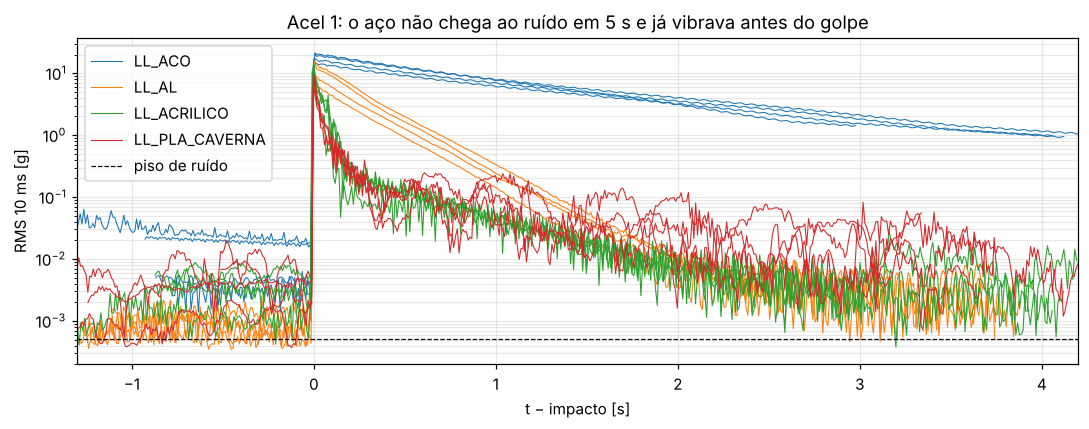

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
for cfg, col in [("LL_ACO", "C0"), ("LL_AL", "C1"), ("LL_ACRILICO", "C2"), ("LL_PLA_CAVERNA", "C3")]:
    for j, e in enumerate(cat.by_config()[cfg][:4]):
        r = read_ni_csv("data/raw/" + e.path)
        fs = r.fs_hz
        P = q.find_pulses(r.data[2], fs)
        i0 = P[q.main_pulse(P)].i_start
        s = q.short_time_rms(r.data[0], fs)
        tt = (np.arange(s.size) * 0.01) - i0 / fs
        ax.semilogy(tt, s, color=col, lw=0.7, label=cfg if j == 0 else None)
ax.axhline(floor["a0"], color="k", ls="--", lw=0.8, label="piso de ruído")
ax.set_xlabel("t − impacto [s]")
ax.set_ylabel("RMS 10 ms [g]")
ax.set_xlim(-1.3, 4.2)
ax.legend()
ax.grid(True, which="both", alpha=0.3)
ax.set_title("Acel 1: o aço não chega ao ruído em 5 s e já vibrava antes do golpe")
plt.tight_layout()

## 4. Offset DC antes do golpe
Com acoplamento AC (corte em 0,5 Hz) o nível médio deve ser ~0. Mediana do trecho
pré-impacto, em mg:

In [7]:
dc = c2.groupby("config")[["a0_dc_pre", "a1_dc_pre"]].agg(lambda s: np.median(np.abs(s)) * 1e3)
dc.columns = ["|DC| Acel 1 [mg]", "|DC| Acel 2 [mg]"]
print(dc.round(3).to_string())
print("\nForça: mediana do registro inteiro por config [N]:")
print(c2.groupby("config")["F_noise_sigma"].median().round(3).to_string())

                     |DC| Acel 1 [mg]  |DC| Acel 2 [mg]
config                                                 
LL_ACO                          2.726             2.069
LL_ACRILICO                     2.748             1.760
LL_AL                           3.445             1.602
LL_FIB_CARBONO                  2.635             1.685
LL_FIB_VIDRO_0                  2.169             1.849
LL_FIB_VIDRO_90                 2.355             3.193
LL_PLA_CAVERNA                  2.659             2.422
LL_PLA_LONGARINA_0              2.230             1.660
LL_PLA_LONGARINA_90             3.071             1.633

Força: mediana do registro inteiro por config [N]:
config
LL_ACO                 0.029
LL_ACRILICO            0.031
LL_AL                  0.025
LL_FIB_CARBONO         0.027
LL_FIB_VIDRO_0         0.028
LL_FIB_VIDRO_90        0.025
LL_PLA_CAVERNA         0.025
LL_PLA_LONGARINA_0     0.035
LL_PLA_LONGARINA_90    0.030


## 5. Tabela por registro (vai para o catálogo na Etapa 1.5)

In [8]:
cols = ["id", "a0_n_clipped", "a1_n_clipped", "a0_snr_db", "a1_snr_db", "a0_decay_db",
        "a0_end_over_floor_db", "a0_pre_over_floor_db"]
c2[cols].round(1).to_csv("docs/reports/fase1/04_resposta_por_registro.csv", index=False)
print(c2[cols].round(1).head(20).to_string(index=False))

            id  a0_n_clipped  a1_n_clipped  a0_snr_db  a1_snr_db  a0_decay_db  a0_end_over_floor_db  a0_pre_over_floor_db
     LL_ACO_01             0           0.0       91.9       92.3        -22.8                  69.1                  36.2
     LL_ACO_02             0           0.0       90.0       90.4        -24.6                  65.5                  19.0
     LL_ACO_03             0           0.0       91.4       91.8        -24.9                  66.6                  16.4
     LL_ACO_04             0           0.0       88.8       89.3        -22.9                  65.9                  31.7
     LL_ACO_05             0           0.0       86.3       86.7        -22.4                  63.8                  34.7
     LL_ACO_06             0           0.0       90.1       90.5        -23.6                  66.5                  33.9
     LL_ACO_07             0           0.0       88.7       89.1        -24.1                  64.5                  41.1
     LL_ACO_08          